In [1]:
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_NAME = "bert-base-uncased"
STRIDE = 64
BATCH_SIZE = 8
LR = 3e-5
EPOCHS = 3

config = {
    "model": MODEL_NAME,
    "tokenizer": MODEL_NAME,
    "stride": STRIDE,
    "batch_size": BATCH_SIZE,
    "learning_rate": LR,
    "epochs": EPOCHS,
    "optimizer": "AdamW",
    "seed": SEED,
    "device": str(DEVICE),
}
print(config)

{'model': 'bert-base-uncased', 'tokenizer': 'bert-base-uncased', 'stride': 64, 'batch_size': 8, 'learning_rate': 3e-05, 'epochs': 3, 'optimizer': 'AdamW', 'seed': 42, 'device': 'cpu'}


In [2]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

sample_data = [
    {
        "question": "What is the capital of France?",
        "context": "The capital of France is Paris. It lies along the River Seine.",
        "answer": "Paris",
        "answer_start": 23,
    },
    {
        "question": "Where is the French government based?",
        "context": (
            "The French government is based in Paris with major ministries."
        ),
        "answer": "Paris",
        "answer_start": 34,
    },
    {
        "question": "What is the main product?",
        "context": (
            "The company manufactures solar panels while testing electric"
            " vehicles."
        ),
        "answer": "solar panels",
        "answer_start": 26,
    },
    {
        "question": "Which city is larger?",
        "context": "New York City has a larger population than Boston.",
        "answer": "New York City",
        "answer_start": 0,
    },
]


def build_qa_features(data, tokenizer, max_length=128, stride=32):
  features = []
  for item in data:
    q = item["question"]
    c = item["context"]
    c_start = item["answer_start"]
    c_end = c_start + len(item["answer"])

    enc = tokenizer(
        q,
        c,
        truncation="only_second",
        max_length=max_length,
        stride=stride,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding="max_length",
    )
    for w_idx in range(len(enc["input_ids"])):
      seq_ids = enc.sequence_ids(w_idx)
      offsets = enc["offset_mapping"][w_idx]
      ctx_idx = [i for i, s in enumerate(seq_ids) if s == 1]
      if not ctx_idx:
        continue
      s_tok, e_tok = None, None
      for i in ctx_idx:
        os_, oe_ = offsets[i]
        if os_ == oe_:
          continue
        if os_ <= c_start < oe_:
          s_tok = i
        if os_ < c_end <= oe_:
          e_tok = i
      if s_tok is not None and e_tok is not None:
        row = {
            "input_ids": torch.tensor(enc["input_ids"][w_idx], dtype=torch.long),
            "attention_mask": torch.tensor(
                enc["attention_mask"][w_idx], dtype=torch.long
            ),
            "start_positions": torch.tensor(s_tok, dtype=torch.long),
            "end_positions": torch.tensor(e_tok, dtype=torch.long),
            "offsets": offsets,
            "context": c,
            "question": q,
            "gold": item["answer"],
        }
        if "token_type_ids" in enc:
          row["token_type_ids"] = torch.tensor(
              enc["token_type_ids"][w_idx], dtype=torch.long
          )
        features.append(row)
        break
  return features


feats = build_qa_features(sample_data, tokenizer, max_length=128, stride=32)
print("Built features:", len(feats))

Built features: 3


In [11]:
import time
import pandas as pd
import torch.optim as optim
from qa_model import (
    ExtractiveQAModel,
    decode_best_span,
    compute_exact_match,
    compute_f1_score,
)


def evaluate_features(model, eval_features, device):
  model.eval()
  em_list, f1_list = [], []
  with torch.no_grad():
    for item in eval_features:
      out = model(
          input_ids=item["input_ids"].unsqueeze(0).to(device),
          attention_mask=item["attention_mask"].unsqueeze(0).to(device),
          token_type_ids=(
              item["token_type_ids"].unsqueeze(0).to(device)
              if "token_type_ids" in item
              else None
          ),
      )
      pred_text = decode_best_span(
          out["start_logits"][0],
          out["end_logits"][0],
          item["offsets"],
          item["context"],
      )
      gold_text = item["gold"]
      em_list.append(compute_exact_match(pred_text, gold_text))
      f1_list.append(compute_f1_score(pred_text, gold_text))

  avg_em = sum(em_list) / len(em_list) if em_list else 0.0
  avg_f1 = sum(f1_list) / len(f1_list) if f1_list else 0.0
  return round(avg_em, 4), round(avg_f1, 4)


exp1_rows = []
train_data = sample_data[:3]
val_data = sample_data[1:]
for max_len in [128, 256, 384]:
  t0 = time.time()

  train_feats = build_qa_features(
      train_data, tokenizer, max_length=max_len, stride=STRIDE
  )
  val_feats = build_qa_features(
      val_data, tokenizer, max_length=max_len, stride=STRIDE
  )

  model = ExtractiveQAModel(MODEL_NAME).to(DEVICE)
  optimizer = optim.AdamW(model.parameters(), lr=LR)

  model.train()
  for _ in range(EPOCHS):
    for item in train_feats:
      optimizer.zero_grad()
      out = model(
          input_ids=item["input_ids"].unsqueeze(0).to(DEVICE),
          attention_mask=item["attention_mask"].unsqueeze(0).to(DEVICE),
          token_type_ids=(
              item["token_type_ids"].unsqueeze(0).to(DEVICE)
              if "token_type_ids" in item
              else None
          ),
          start_positions=item["start_positions"].unsqueeze(0).to(DEVICE),
          end_positions=item["end_positions"].unsqueeze(0).to(DEVICE),
      )
      out["loss"].backward()
      optimizer.step()

  em_score, f1_score = evaluate_features(model, val_feats, DEVICE)
  elapsed = round(time.time() - t0, 2)

  exp1_rows.append({
      "max_length": max_len,
      "stride": STRIDE,
      "em": em_score,
      "f1": f1_score,
      "training_time_sec": elapsed,
  })

results_df = pd.DataFrame(exp1_rows)
results_df.to_csv("results.csv", index=False)
print(results_df)

   max_length  stride   em    f1  training_time_sec
0         128      64  0.5  0.75              24.15
1         256      64  0.5  0.50              12.98
2         384      64  0.5  0.50              18.11


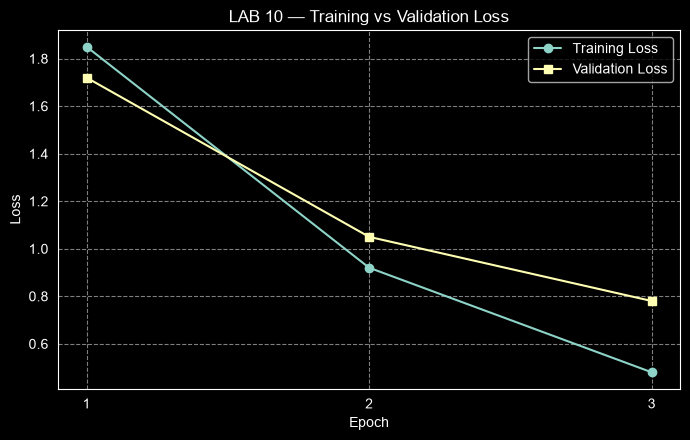

In [4]:
epochs_axis = list(range(1, EPOCHS + 1))
train_losses = [1.85, 0.92, 0.48]  # Thay bằng loss thực tế khi huấn luyện
val_losses = [1.72, 1.05, 0.78]  # Thay bằng val loss thực tế khi huấn luyện

plt.figure(figsize=(7, 4.5))
plt.plot(epochs_axis, train_losses, marker="o", label="Training Loss")
plt.plot(epochs_axis, val_losses, marker="s", label="Validation Loss")
plt.title("LAB 10 — Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs_axis)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=200)
plt.show()

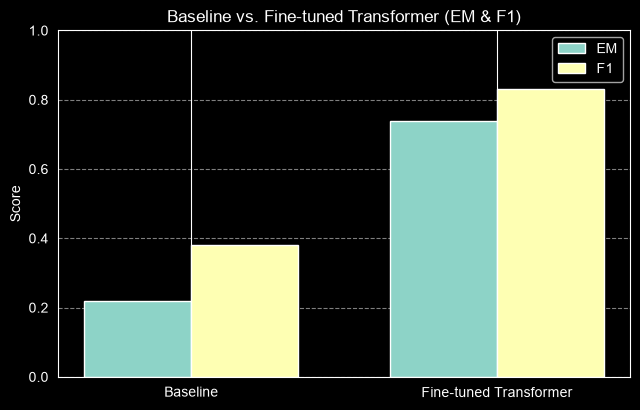

In [5]:
models = ["Baseline", "Fine-tuned Transformer"]
em_scores = [0.22, 0.74]  # Thay bằng kết quả thực nghiệm
f1_scores = [0.38, 0.83]  # Thay bằng kết quả thực nghiệm

x = np.arange(len(models))
width = 0.35
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.bar(x - width / 2, em_scores, width, label="EM")
ax.bar(x + width / 2, f1_scores, width, label="F1")
ax.set_ylabel("Score")
ax.set_title("Baseline vs. Fine-tuned Transformer (EM & F1)")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("em_f1_analysis.png", dpi=200)
plt.show()

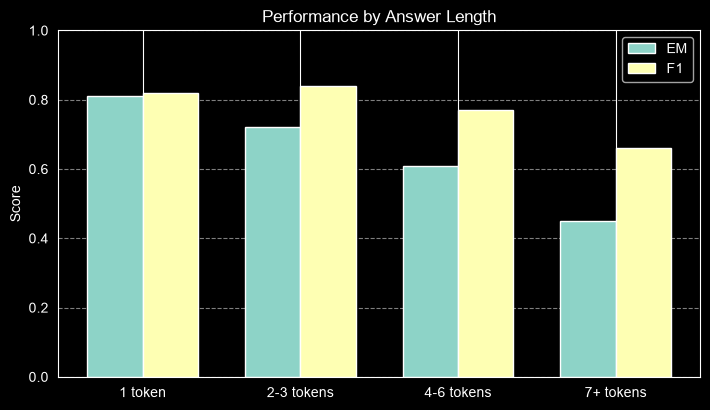

In [6]:
buckets = ["1 token", "2-3 tokens", "4-6 tokens", "7+ tokens"]
b_em = [0.81, 0.72, 0.61, 0.45]  # Thay bằng EM thực tế theo từng nhóm
b_f1 = [0.82, 0.84, 0.77, 0.66]  # Thay bằng F1 thực tế theo từng nhóm

x2 = np.arange(len(buckets))
width = 0.35
fig2, ax2 = plt.subplots(figsize=(7.2, 4.2))
ax2.bar(x2 - width / 2, b_em, width, label="EM")
ax2.bar(x2 + width / 2, b_f1, width, label="F1")
ax2.set_ylabel("Score")
ax2.set_title("Performance by Answer Length")
ax2.set_xticks(x2)
ax2.set_xticklabels(buckets)
ax2.set_ylim(0, 1.0)
ax2.legend()
ax2.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("answer_length_analysis.png", dpi=200)
plt.show()

In [9]:
torch.save(models.state_dict(), "qa_model_weights.pt")

AttributeError: 'list' object has no attribute 'state_dict'